# ResNet from scratch, one step at a time 🧱

> **Twin of:** [`../resnet.ipynb`](../resnet.ipynb). That notebook reproduces the library code; this one **builds ResNet from
> nothing** in plain PyTorch, explaining and *drawing* every step, for readers who have never seen a CNN.
>
> **Paper:** He, Zhang, Ren & Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016 ([arXiv:1512.03385](https://arxiv.org/abs/1512.03385))
>
> **You need:** basic Python and the idea of a matrix. Everything else is introduced on the way.

**The journey (each box is one section of this notebook):**

```mermaid
flowchart LR
    A["1. An image is<br/>a tensor"] --> B["2. Convolution<br/>by hand"] --> C["3. The stem<br/>conv→BN→ReLU→pool"] --> D["4. Why deep nets<br/>get worse"]
    D --> E["5. The residual<br/>block"] --> F["6. Bottleneck<br/>block"] --> G["7. Stack blocks into<br/>ResNet-18"] --> H["8. Why it trains:<br/>plain vs residual"] --> I["9. Checks &<br/>library twin"]
```

**Colour code used in every picture:** 🟨 what the step is looking at · 🟦 the other operand (kernel) · 🟩 output · 🟪 the residual / skip path.

## 0. Setup

The kit `stepviz` only draws pictures (matplotlib + Pillow). Every model in this notebook is written by hand with `torch.nn`.

In [1]:
import sys
from pathlib import Path

# Find the notebook kit (it lives in <repo>/notebooks/_from_scratch_kit).
KIT = next(p / "notebooks" / "_from_scratch_kit" for p in [Path.cwd(), *Path.cwd().parents]
           if (p / "notebooks" / "_from_scratch_kit").is_dir())
sys.path.insert(0, str(KIT))

import torch
import torch.nn as nn
import torch.nn.functional as F
import stepviz as sv
from stepviz import diagrams, ops, tensors as T

torch.manual_seed(0)
torch.set_num_threads(2)
print("torch", torch.__version__)

torch 2.13.0


## 1. An image is a tensor

A colour image is three grids of numbers, one per colour channel (red, green, blue). PyTorch stores a **batch** of images as a 4-D tensor of shape `(B, C, H, W)`: batch size, channels, height, width.

We use a small synthetic image (a red square, a green disc and a blue bar) so we can predict what each layer should notice: edges, colours and blobs.

image tensor shape (B, C, H, W): (1, 3, 64, 64)


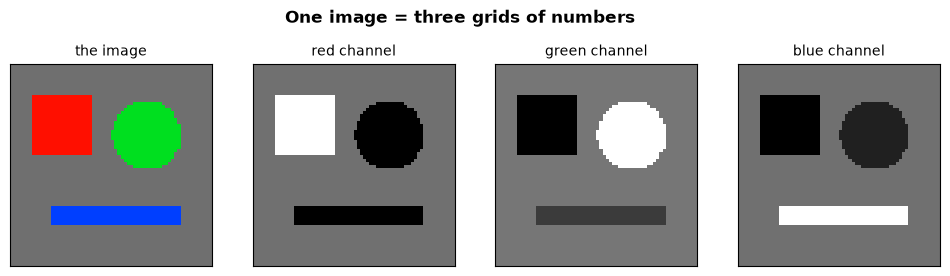

In [2]:
def synthetic_image(size: int = 64) -> torch.Tensor:
    """(1, 3, size, size) image: red square, green disc and blue bar on a grey background."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.45)
    square = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in [(square, (0.9, 0.15, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.3, 0.9))]:
        for c in range(3):
            img[c][mask] = rgb[c]
    return img[None]

x = synthetic_image(64)
print("image tensor shape (B, C, H, W):", tuple(x.shape))
T.panels({"the image": x, "red channel": x[:, 0:1], "green channel": x[:, 1:2],
          "blue channel": x[:, 2:3]}, title="One image = three grids of numbers")

## 2. Convolution, by hand

A **convolution** slides a small grid of weights (the *kernel*, e.g. 3×3) over the image. At every position it multiplies the kernel with the patch underneath, element by element, and adds everything up into **one** output number. Where the patch looks like the kernel, the output is large.

```mermaid
flowchart LR
    P["3×3 patch<br/>of the input"] --> M["multiply<br/>element-wise"]
    K["3×3 kernel<br/>(learned weights)"] --> M
    M --> S["sum the 9<br/>products"] --> O["one output<br/>pixel"]
```

Below is a vertical-edge kernel (`-1 0 +1` in every row) sliding over a 6×6 picture of a step edge. Watch the output light up exactly where dark meets bright.

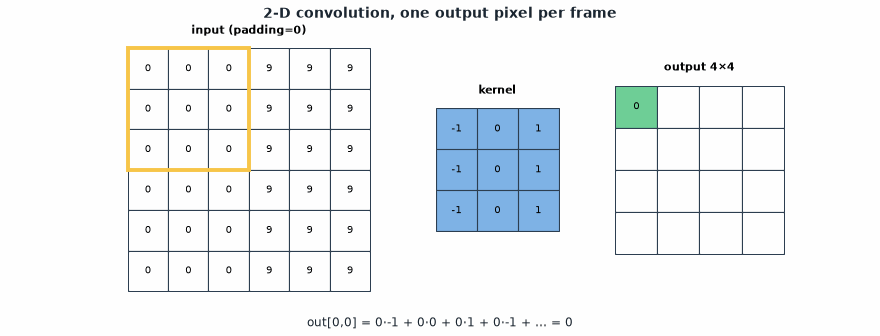

hand-computed output == F.conv2d ✅
 tensor([[ 0., 27., 27.,  0.],
        [ 0., 27., 27.,  0.],
        [ 0., 27., 27.,  0.],
        [ 0., 27., 27.,  0.]])


In [3]:
edge_img = torch.tensor([[0, 0, 0, 9, 9, 9]] * 6, dtype=torch.float32)
vertical_edge = torch.tensor([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=torch.float32)
out = ops.conv2d_animation(edge_img, vertical_edge, stride=1, padding=0, max_frames=10)

# The hand-made animation must agree with PyTorch's convolution.
torch_out = F.conv2d(edge_img[None, None], vertical_edge[None, None])[0, 0]
assert torch.allclose(torch.tensor(out), torch_out), "animation and F.conv2d disagree"
print("hand-computed output == F.conv2d ✅\n", torch_out)

### Stride and padding: the output-size formula

* **stride `s`**: how far the kernel jumps each step. Stride 2 halves the output size.
* **padding `p`**: zeros added around the border so the kernel can sit on edge pixels.

$$H_{out} = \left\lfloor \frac{H_{in} + 2p - k}{s} \right\rfloor + 1$$

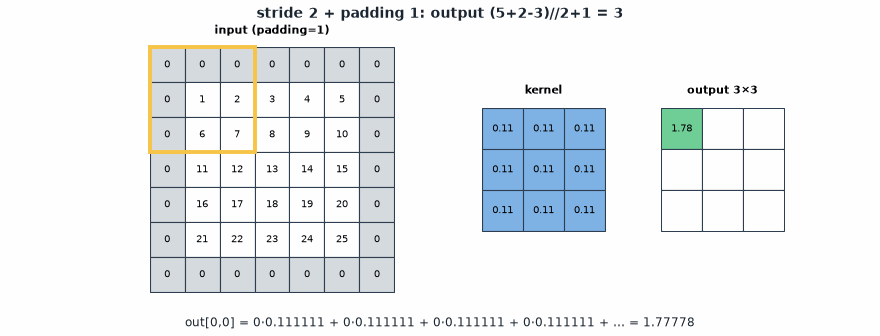

In [4]:
small = torch.arange(1, 26, dtype=torch.float32).reshape(5, 5)
ones = torch.ones(3, 3) / 9          # a "blur" kernel: the average of the 3x3 patch
out = ops.conv2d_animation(small, ones, stride=2, padding=1, max_frames=9,
                           title="stride 2 + padding 1: output (5+2-3)//2+1 = 3")
assert torch.allclose(torch.tensor(out), F.conv2d(small[None, None], ones[None, None],
                                                  stride=2, padding=1)[0, 0], atol=1e-5)

A real conv layer has **many** kernels (one per output channel), and each kernel spans **all** input channels. `nn.Conv2d(3, 64, 7)` holds 64 kernels of shape 3×7×7, so it produces 64 feature maps.

## 3. The stem: conv 7×7 → BatchNorm → ReLU → max-pool

The **stem** quickly shrinks the image 4× while turning 3 colour channels into 64 feature channels. Small feature maps make the rest of the network cheap.

```mermaid
flowchart LR
    IN["image<br/>3×64×64"]:::io --> C["conv 7×7, stride 2<br/>64 kernels"] --> B["BatchNorm<br/>re-centre & scale"] --> R["ReLU<br/>keep positives"] --> P["max-pool 3×3<br/>stride 2"] --> OUT["64×16×16"]:::io
    classDef io fill:#F5B041,stroke:#2C3E50
```

### 3.1 The 7×7 convolution

after conv 7×7 / stride 2: (1, 64, 32, 32)  (64 channels, (64+6-7)//2+1 = 32 pixels)


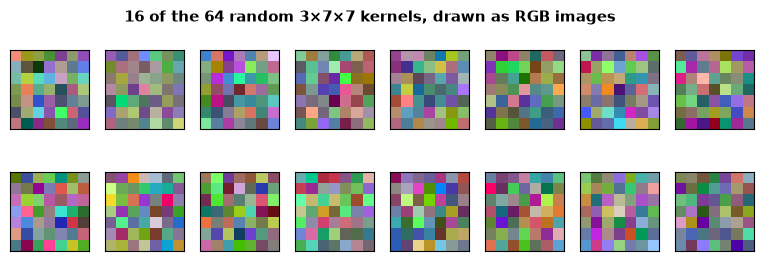

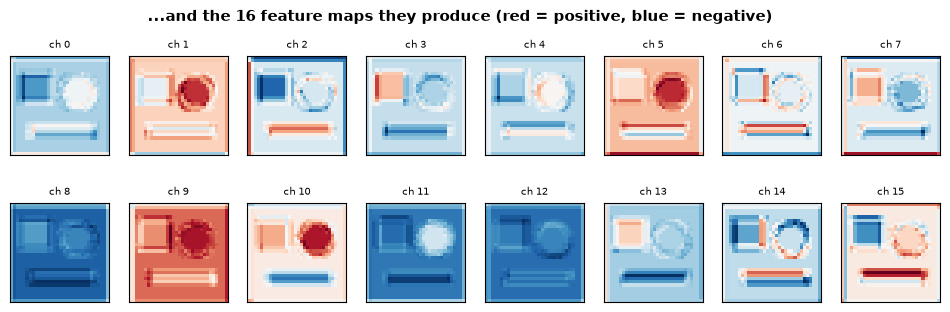

In [5]:
conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
nn.init.kaiming_normal_(conv1.weight, mode="fan_out", nonlinearity="relu")   # the paper's initialisation
with torch.no_grad():
    a1 = conv1(x)
print("after conv 7×7 / stride 2:", tuple(a1.shape), " (64 channels, (64+6-7)//2+1 = 32 pixels)")
T.kernels(conv1.weight, n=16, title="16 of the 64 random 3×7×7 kernels, drawn as RGB images")
T.feature_maps(a1, n=16, title="...and the 16 feature maps they produce (red = positive, blue = negative)")

The kernels are random right now, so the maps are noisy versions of the image. Training would turn the kernels into edge and colour detectors. Even so, the shapes are already visible.

### 3.2 BatchNorm: put every channel on the same scale

For each channel, BatchNorm subtracts the mean and divides by the standard deviation (computed over the batch and all pixels), then applies a learned scale `γ` and shift `β`:

$$\hat{x} = \frac{x - \mu_c}{\sqrt{\sigma_c^2 + \epsilon}}, \qquad y = \gamma_c\,\hat{x} + \beta_c$$

This keeps the numbers in a healthy range layer after layer, which makes training faster and more stable.

hand-written BatchNorm == nn.BatchNorm2d ✅


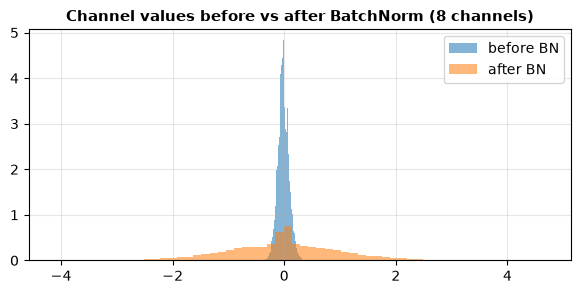

In [6]:
bn1 = nn.BatchNorm2d(64)
bn1.train()                                  # use this batch's statistics, like during training
batch = torch.cat([synthetic_image(64), torch.rand(3, 3, 64, 64)])     # 4 images, so statistics make sense
with torch.no_grad():
    pre = conv1(batch)
    post = bn1(pre)

# BatchNorm written out by hand, to prove the formula above is all it does
mu = pre.mean(dim=(0, 2, 3), keepdim=True)
var = pre.var(dim=(0, 2, 3), unbiased=False, keepdim=True)
by_hand = (pre - mu) / torch.sqrt(var + bn1.eps) * bn1.weight[None, :, None, None] + bn1.bias[None, :, None, None]
assert torch.allclose(by_hand, post, atol=1e-5)
print("hand-written BatchNorm == nn.BatchNorm2d ✅")
T.histogram({"before BN": pre[:, :8], "after BN": post[:, :8]},
            title="Channel values before vs after BatchNorm (8 channels)")

### 3.3 ReLU: keep what fired, zero the rest

`ReLU(x) = max(0, x)`. This simple bend is what lets stacked layers represent more than one big linear map.

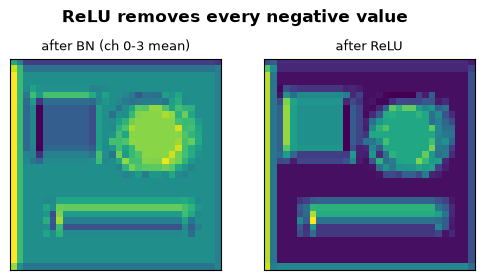

fraction of zeros after ReLU: 49%


In [7]:
relu_out = F.relu(post[:1])
T.panels({"after BN (ch 0-3 mean)": post[:1, :4], "after ReLU": relu_out[:, :4]}, kind="map",
         title="ReLU removes every negative value")
print(f"fraction of zeros after ReLU: {(relu_out == 0).float().mean():.0%}")

### 3.4 Max-pooling: keep the strongest response in each window

Max-pooling slides a window and keeps only the **largest** value. The map halves in size, and a small shift of the object barely changes the result.

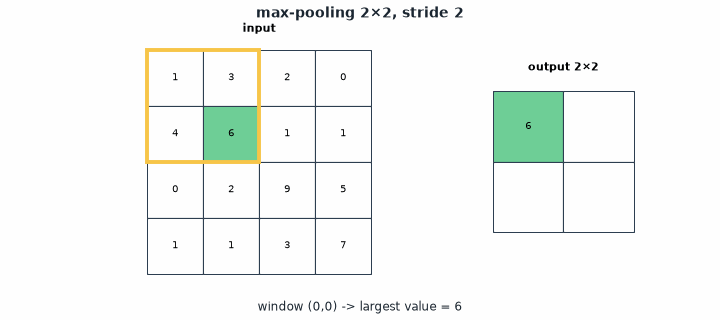

In [8]:
demo = torch.tensor([[1, 3, 2, 0], [4, 6, 1, 1], [0, 2, 9, 5], [1, 1, 3, 7]], dtype=torch.float32)
pooled = ops.pool_animation(demo, size=2, stride=2, mode="max")
assert torch.equal(torch.tensor(pooled), F.max_pool2d(demo[None, None], 2)[0, 0])

### 3.5 The complete stem

stem output: (1, 64, 16, 16) = 4× smaller, 64 channels


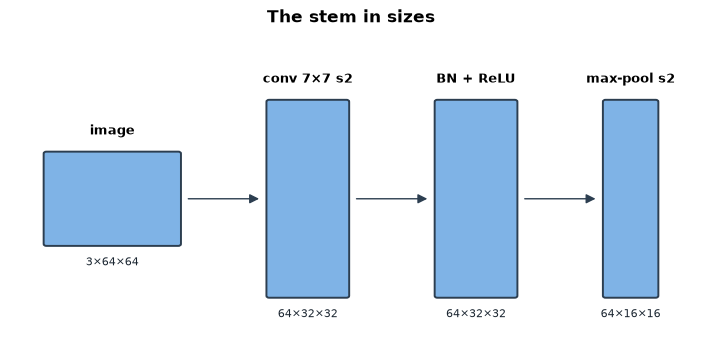

In [9]:
stem = nn.Sequential(
    nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
    nn.BatchNorm2d(64),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
)
with torch.no_grad():
    s = stem.eval()(x)
print("stem output:", tuple(s.shape), "= 4× smaller, 64 channels")
diagrams.tensor_journey([("image", (3, 64, 64)), ("conv 7×7 s2", (64, 32, 32)),
                         ("BN + ReLU", (64, 32, 32)), ("max-pool s2", (64, 16, 16))],
                        title="The stem in sizes")

## 4. Why simply stacking more layers fails

Before ResNet, people found something surprising: a 56-layer plain CNN had **higher training error** than a 20-layer one. This is not overfitting. The deeper network was harder to *optimise*. A deep network can always copy a shallow one by making its extra layers do nothing (the identity), but gradient descent struggles to find that solution through a long chain of layers.

**ResNet's idea:** let each block learn only a **correction** `F(x)` to its input and add the input back:

$$y = \mathrm{ReLU}\big(F(x) + x\big)$$

If the best thing a block can do is nothing, it only has to push `F(x)` to zero, which is easy. The `+ x` path (the **skip connection**) also gives gradients a direct route back to early layers.

```mermaid
flowchart TB
    X["x"] --> C1["conv 3×3 → BN → ReLU"] --> C2["conv 3×3 → BN"] --> ADD(("+"))
    X -. "skip: identity" .-> ADD
    ADD --> R["ReLU"] --> Y["y = ReLU(F(x) + x)"]
    style ADD fill:#B98ADB
```

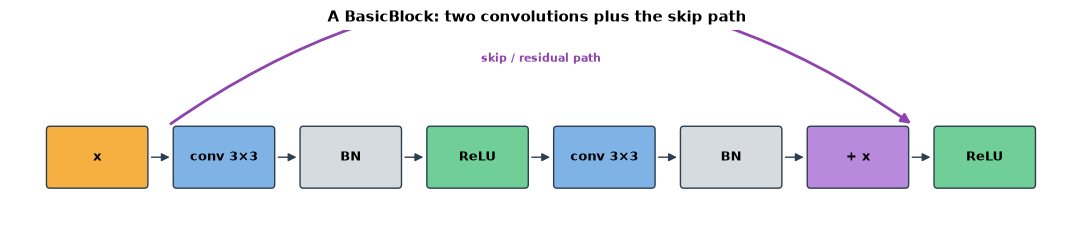

In [10]:
diagrams.block_diagram([("x", "input"), ("conv 3×3", "compare"), ("BN", "muted"), ("ReLU", "done"),
                        ("conv 3×3", "compare"), ("BN", "muted"), ("+ x", "accent"), ("ReLU", "done")],
                       skip=(1, 6), title="A BasicBlock: two convolutions plus the skip path")

## 5. The residual block (BasicBlock), step by step

We build it in pieces and look at the tensor after **each** piece. The attribute names (`conv1`, `bn1`, `conv2`, `bn2`, `downsample`) match the HaleBlocks implementation, so section 9 can load its weights.

In [11]:
class BasicBlock(nn.Module):
    """Two 3×3 convolutions with a skip connection: y = ReLU(F(x) + shortcut(x))."""

    expansion = 1      # output channels = planes * expansion

    def __init__(self, in_planes: int, planes: int, stride: int = 1) -> None:
        super().__init__()
        # F(x): the residual branch. The first conv may downsample (stride 2).
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        # The shortcut must output the same shape as F(x). If the size or channel count changes,
        # a 1×1 convolution (a "projection") reshapes x; otherwise x is passed through unchanged.
        self.downsample = None
        if stride != 1 or in_planes != planes:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_planes, planes, 1, stride=stride, bias=False), nn.BatchNorm2d(planes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x if self.downsample is None else self.downsample(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + identity)

Now we run one block piece by piece on the stem output and draw each intermediate tensor.

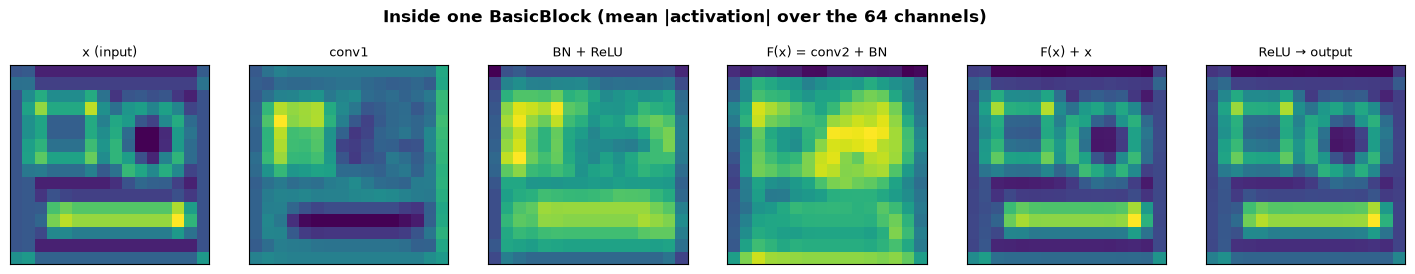

In [12]:
block = BasicBlock(64, 64).eval()
with torch.no_grad():
    h = s                                                # stem output, 64×16×16
    step1 = block.conv1(h)
    step2 = F.relu(block.bn1(step1))
    step3 = block.bn2(block.conv2(step2))                # F(x)
    step4 = step3 + h                                    # F(x) + x
    step5 = F.relu(step4)                                # block output
assert torch.allclose(step5, block(h), atol=1e-6)        # the pieces really are the block
T.panels({"x (input)": h, "conv1": step1, "BN + ReLU": step2, "F(x) = conv2 + BN": step3,
          "F(x) + x": step4, "ReLU → output": step5}, kind="map", cols=6,
         title="Inside one BasicBlock (mean |activation| over the 64 channels)")

The same thing as an animation, one sub-step per frame, with the shape and a one-line explanation:

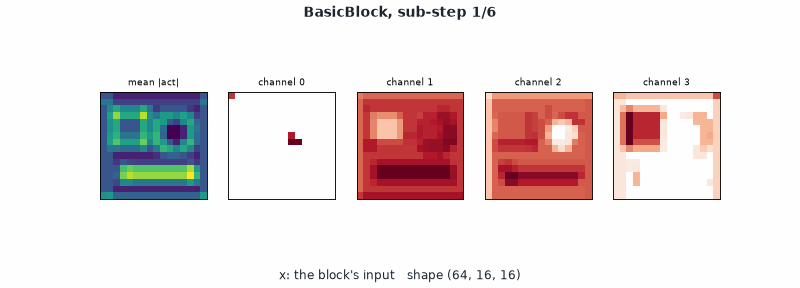

In [13]:
pieces = [("x: the block's input", h), ("conv1: 64 kernels of 3×3×64", step1),
          ("BN + ReLU: rescale, keep positives", step2), ("conv2 + BN: this is F(x)", step3),
          ("F(x) + x: add the skip path", step4), ("ReLU: the block's output", step5)]
anim = sv.Animator(figsize=(10, 3.6), ms_per_frame=1300)
for i, (label, t) in enumerate(pieces):
    with anim.frame() as fig:
        sv.heading(fig, f"BasicBlock, sub-step {i + 1}/{len(pieces)}")
        axes = fig.subplots(1, 5)
        mean_ax, chans = axes[0], axes[1:]
        mean_ax.imshow(t[0].abs().mean(0), cmap="viridis")
        mean_ax.set_title("mean |act|", fontsize=8)
        for c, ax in enumerate(chans):
            ch = t[0, c]
            m = float(ch.abs().max()) or 1.0
            ax.imshow(ch, cmap="RdBu_r", vmin=-m, vmax=m)
            ax.set_title(f"channel {c}", fontsize=8)
        for ax in axes:
            ax.set_xticks([]); ax.set_yticks([])
        sv.caption(fig, f"{label}   shape {tuple(t.shape[1:])}")
anim.show()

### 5.1 When the shape changes: the projection shortcut

At the start of stages 1-3 the block halves the resolution (stride 2) and doubles the channels. `x` no longer has the same shape as `F(x)`, so it cannot be added directly. A **1×1 convolution with stride 2** reshapes it. A 1×1 conv mixes channels at each pixel without looking at neighbours.

In [14]:
down_block = BasicBlock(64, 128, stride=2).eval()
with torch.no_grad():
    fx = down_block.bn2(down_block.conv2(F.relu(down_block.bn1(down_block.conv1(s)))))
    shortcut = down_block.downsample(s)
print("input x      :", tuple(s.shape))
print("F(x)         :", tuple(fx.shape), " <- stride-2 conv halved H, W and doubled channels")
print("projection(x):", tuple(shortcut.shape), " <- 1×1 conv, stride 2: now the shapes match")
print("x + F(x) would fail without it:", s.shape != fx.shape)

input x      : (1, 64, 16, 16)
F(x)         : (1, 128, 8, 8)  <- stride-2 conv halved H, W and doubled channels
projection(x): (1, 128, 8, 8)  <- 1×1 conv, stride 2: now the shapes match
x + F(x) would fail without it: True


## 6. The bottleneck block (ResNet-50 and deeper)

Two 3×3 convolutions on 256 channels are expensive. The **bottleneck** first squeezes the channels with a 1×1 conv, does the 3×3 work on the thin tensor, then expands back with another 1×1:

```mermaid
flowchart LR
    X["x: 256 ch"] --> A["1×1 conv<br/>256 → 64<br/>(squeeze)"] --> B["3×3 conv<br/>64 → 64<br/>(spatial work)"] --> C["1×1 conv<br/>64 → 256<br/>(expand)"] --> ADD(("+")) --> Y["y: 256 ch"]
    X -. skip .-> ADD
    style ADD fill:#B98ADB
```

In [15]:
class Bottleneck(nn.Module):
    """1×1 squeeze → 3×3 → 1×1 expand (×4), plus the skip connection."""

    expansion = 4

    def __init__(self, in_planes: int, planes: int, stride: int = 1) -> None:
        super().__init__()
        out_planes = planes * self.expansion
        self.conv1 = nn.Conv2d(in_planes, planes, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, out_planes, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_planes)
        self.downsample = None
        if stride != 1 or in_planes != out_planes:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_planes, out_planes, 1, stride=stride, bias=False), nn.BatchNorm2d(out_planes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x if self.downsample is None else self.downsample(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return F.relu(out + identity)


def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

two_3x3 = nn.Sequential(nn.Conv2d(256, 256, 3, padding=1, bias=False), nn.Conv2d(256, 256, 3, padding=1, bias=False))
print(f"two 3×3 convs on 256 channels : {n_params(two_3x3):>9,} weights")
print(f"bottleneck 256→64→64→256      : {n_params(Bottleneck(256, 64)):>9,} weights (incl. BN)")
print(f"-> about {n_params(two_3x3) / n_params(Bottleneck(256, 64)):.0f}× cheaper for the same input/output size")

two 3×3 convs on 256 channels : 1,179,648 weights
bottleneck 256→64→64→256      :    70,400 weights (incl. BN)
-> about 17× cheaper for the same input/output size


## 7. Stacking blocks into ResNet-18

ResNet-18 = stem + 4 **stages** of 2 BasicBlocks each + global average pooling. Each new stage halves the resolution and doubles the channels:

```mermaid
flowchart LR
    IN["image 3×H×W"] --> STEM["stem<br/>64×H/4"] --> S0["stage0<br/>2 blocks<br/>64×H/4"] --> S1["stage1<br/>2 blocks<br/>128×H/8"] --> S2["stage2<br/>2 blocks<br/>256×H/16"] --> S3["stage3<br/>2 blocks<br/>512×H/32"] --> POOL["global avg pool<br/>512"]
```

pooled vector: (1, 512)
stage0 map  : (1, 64, 16, 16)  stride 4
stage1 map  : (1, 128, 8, 8)  stride 8
stage2 map  : (1, 256, 4, 4)  stride 16
stage3 map  : (1, 512, 2, 2)  stride 32
parameters   : 11,176,512  (paper: 11.7M incl. the 1000-class head)


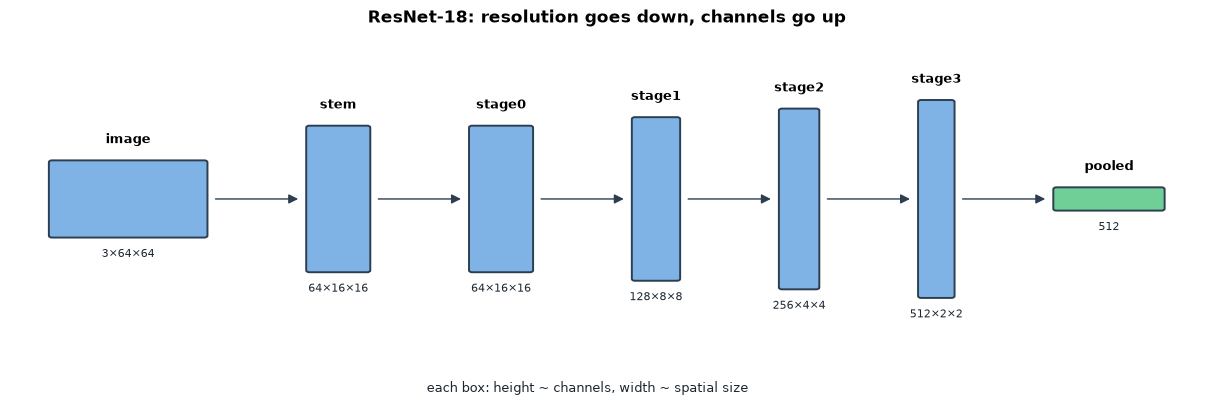

In [16]:
class ResNet(nn.Module):
    """stem → stage0..stage3 → global average pool. Returns (pooled vector, list of stage maps)."""

    def __init__(self, block, layers, in_chans: int = 3) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 64, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(64),
            nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        widths = [64, 128, 256, 512]
        in_planes = 64
        for i, (planes, n_blocks) in enumerate(zip(widths, layers)):
            stride = 1 if i == 0 else 2                 # stage0 keeps the size, the others halve it
            blocks = []
            for b in range(n_blocks):
                blocks.append(block(in_planes, planes, stride if b == 0 else 1))
                in_planes = planes * block.expansion
            setattr(self, f"stage{i}", nn.Sequential(*blocks))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.embed_dim = in_planes
        for m in self.modules():                         # the paper's initialisation
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x: torch.Tensor):
        x = self.stem(x)
        maps = []
        for i in range(4):
            x = getattr(self, f"stage{i}")(x)
            maps.append(x)
        return self.pool(x).flatten(1), maps


resnet18 = ResNet(BasicBlock, [2, 2, 2, 2]).eval()
with torch.no_grad():
    pooled, maps = resnet18(x)
print("pooled vector:", tuple(pooled.shape))
for i, m in enumerate(maps):
    print(f"stage{i} map  :", tuple(m.shape), f" stride {64 // m.shape[-1]}")
print(f"parameters   : {n_params(resnet18):,}  (paper: 11.7M incl. the 1000-class head)")
diagrams.tensor_journey([("image", (3, 64, 64)), ("stem", (64, 16, 16)), ("stage0", (64, 16, 16)),
                         ("stage1", (128, 8, 8)), ("stage2", (256, 4, 4)), ("stage3", (512, 2, 2)),
                         ("pooled", (512,))],
                        title="ResNet-18: resolution goes down, channels go up",
                        note="each box: height ~ channels, width ~ spatial size")

### 7.1 A picture after every block

`StepRecorder` hooks every block of the model we just wrote and keeps its output for one forward pass:

  #  module                             type                                input -> output                     params
  0  stem                               Sequential                 (1, 3, 64, 64) -> (1, 64, 16, 16)             9,536
  1  stage0.0                           BasicBlock                (1, 64, 16, 16) -> (1, 64, 16, 16)            73,984
  2  stage0.1                           BasicBlock                (1, 64, 16, 16) -> (1, 64, 16, 16)            73,984
  3  stage1.0                           BasicBlock                (1, 64, 16, 16) -> (1, 128, 8, 8)            230,144
  4  stage1.1                           BasicBlock                 (1, 128, 8, 8) -> (1, 128, 8, 8)            295,424
  5  stage2.0                           BasicBlock                 (1, 128, 8, 8) -> (1, 256, 4, 4)            919,040
  6  stage2.1                           BasicBlock                 (1, 256, 4, 4) -> (1, 256, 4, 4)          1,180,672
  7  stage3.0                           BasicBlo

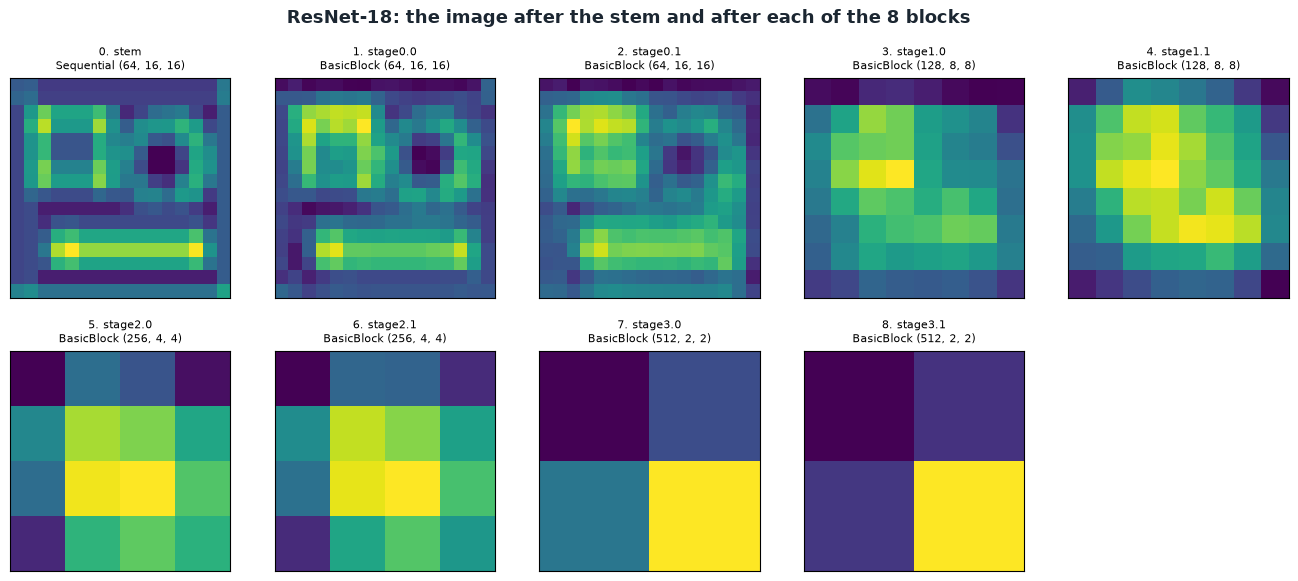

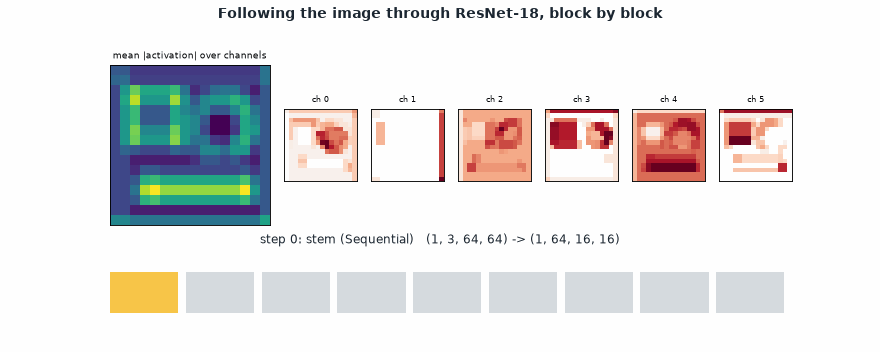

In [17]:
rec = sv.StepRecorder(resnet18, where=lambda name, m: name == "stem" or isinstance(m, BasicBlock))
with rec, torch.no_grad():
    resnet18(synthetic_image(64))
rec.table()
rec.gallery(cols=5, title="ResNet-18: the image after the stem and after each of the 8 blocks")
rec.film(title="Following the image through ResNet-18, block by block")

## 8. Why the skip connections matter: deep plain networks stop learning

Section 4 claimed that a deep *plain* network is hard to optimise. We can test that directly. We train four small networks on the same easy task (which quadrant of an 8×8 image holds a bright blob?) with the same optimiser and the same number of steps:

* **3 blocks**, plain vs residual: both shallow;
* **24 blocks**, plain vs residual: both deep (48 conv layers).

The only difference within each pair is the `+ x` in the block. The prediction from §4: depth hurts the plain network's **training** loss, and the residual network does not care.

```mermaid
flowchart LR
    D["same data,<br/>same optimiser,<br/>120 steps"] --> P3["3 blocks, plain"] & R3["3 blocks, + x"] & P24["24 blocks, plain"] & R24["24 blocks, + x"]
    P3 & R3 & P24 & R24 --> L["compare training loss"]
```

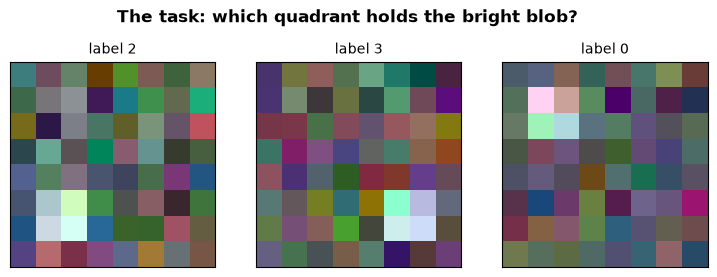

3 blocks, plain        final training loss 0.005
3 blocks, residual     final training loss 0.004
24 blocks, plain       final training loss 0.638
24 blocks, residual    final training loss 0.001


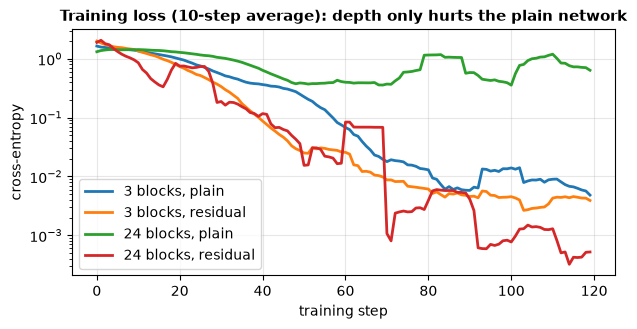

In [18]:
class PlainBlock(BasicBlock):
    """A BasicBlock with the skip connection removed: y = ReLU(F(x))."""

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)))


def quadrant_data(n: int, seed: int = 0):
    """8×8 noisy images; the label says which quadrant (0-3) holds a bright 2×2 blob."""
    g = torch.Generator().manual_seed(seed)
    images = torch.randn(n, 3, 8, 8, generator=g) * 0.5
    labels = torch.randint(0, 4, (n,), generator=g)
    for i in range(n):
        r, c = divmod(int(labels[i]), 2)
        images[i, :, r * 4 + 1:r * 4 + 3, c * 4 + 1:c * 4 + 3] += 2.0
    return images, labels


def train_curve(block_cls, depth: int, steps: int = 120) -> list:
    torch.manual_seed(0)
    net = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), *[block_cls(8, 8) for _ in range(depth)],
                        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(8, 4))
    opt = torch.optim.SGD(net.parameters(), lr=0.05, momentum=0.9)
    images, labels = quadrant_data(512)
    losses = []
    for _ in range(steps):
        idx = torch.randint(0, 512, (32,))
        loss = F.cross_entropy(net(images[idx]), labels[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

T.panels({f"label {int(l)}": im for im, l in zip(*[t[:4] for t in quadrant_data(4, seed=1)])},
         title="The task: which quadrant holds the bright blob?")
curves = {name: train_curve(cls, depth) for name, cls, depth in [
    ("3 blocks, plain", PlainBlock, 3), ("3 blocks, residual", BasicBlock, 3),
    ("24 blocks, plain", PlainBlock, 24), ("24 blocks, residual", BasicBlock, 24)]}
smooth = {k: [sum(v[max(0, i - 9):i + 1]) / len(v[max(0, i - 9):i + 1]) for i in range(len(v))]
          for k, v in curves.items()}
for name, losses in curves.items():
    print(f"{name:22s} final training loss {sum(losses[-10:]) / 10:.3f}")
T.curve(smooth, title="Training loss (10-step average): depth only hurts the plain network",
        xlabel="training step", ylabel="cross-entropy", logy=True)
deep_plain, deep_res = (sum(curves[k][-10:]) / 10 for k in ("24 blocks, plain", "24 blocks, residual"))
assert deep_plain > 10 * deep_res, "expected the deep plain net to train much worse"

The two shallow networks learn the task equally well. The deep plain network has the **same** blocks plus a few more, yet its training loss stays far higher. This is the degradation problem from §4, reproduced. Adding `+ x` to the same 24 blocks removes it completely. That one change is what made 50-, 101- and 152-layer networks trainable.

## 9. Checks, and the library twin

**Sanity checks.** Every parameter must receive a gradient, and the output shapes must follow the stride rule.

In [19]:
resnet18.train().zero_grad()
pooled, maps = resnet18(torch.randn(2, 3, 64, 64))
(pooled.square().mean() + sum(m.square().mean() for m in maps)).backward()
dead = [n for n, p in resnet18.named_parameters() if p.grad is None or not torch.isfinite(p.grad).all()]
assert not dead, dead
assert [m.shape[-1] for m in maps] == [16, 8, 4, 2]
print("every parameter gets a finite gradient ✅   stage strides 4, 8, 16, 32 ✅")

every parameter gets a finite gradient ✅   stage strides 4, 8, 16, 32 ✅


**Is this the same network as the library's?** If HaleBlocks' `hale_core` can be imported, build its ResNet-18, copy *our* weights into it with `strict=True` (this only works if every parameter name and shape matches), and compare the outputs. Without `hale_core` the check is skipped.

In [20]:
try:
    import logging
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _loguru
        _loguru.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone
except ImportError:
    build_vision_backbone = None
    print("hale_core not importable here - skipping the library comparison")

if build_vision_backbone is not None:
    lib = build_vision_backbone("resnet18", img_size=64).eval()
    ours = resnet18.eval()
    missing, unexpected = lib.load_state_dict(ours.state_dict(), strict=False)
    assert not unexpected and not [k for k in missing if not k.startswith(("head", "fc"))], (missing, unexpected)
    probe = torch.randn(2, 3, 64, 64)
    with torch.no_grad():
        lib_out, (our_pooled, our_maps) = lib(probe), ours(probe)
    diff = max((lib_out.pooled_output - our_pooled).abs().max().item(),
               *[(a - b).abs().max().item() for a, b in zip(lib_out.feature_maps, our_maps)])
    print(f"max |library - from-scratch| = {diff:.2e}")
    assert diff < 1e-5
    print("our from-scratch ResNet-18 computes exactly what hale_core's ResNet-18 computes ✅")

max |library - from-scratch| = 0.00e+00
our from-scratch ResNet-18 computes exactly what hale_core's ResNet-18 computes ✅


## 10. Recap

| Step | What it does | Shape (64×64 input) |
|---|---|---|
| conv 7×7 / 2 | 64 learned pattern detectors | 3×64×64 → 64×32×32 |
| BatchNorm | normalise each channel | same |
| ReLU | keep positive responses | same |
| max-pool 3×3 / 2 | keep the strongest response per window | → 64×16×16 |
| BasicBlock | `ReLU(F(x) + x)`; F = two 3×3 convs | same, or ½ size & 2× channels |
| projection shortcut | 1×1 conv so `x` matches `F(x)` | ½ size, 2× channels |
| global avg pool | one number per channel | 512×2×2 → 512 |

**Common mistakes**

* Forgetting the projection when the stride or channel count changes, so `out + identity` fails with a shape error.
* Putting the final ReLU *before* the addition: the paper applies it **after** `F(x) + x`.
* Calling a model in `train()` mode when you mean to evaluate it: BatchNorm then uses batch statistics.

**Try it yourself**

1. Change the edge kernel in §2 to detect **horizontal** edges and check where it fires.
2. Re-run §8 with 40 blocks. Does the deep plain network get even worse? Does the residual one?
3. Build `ResNet(Bottleneck, [3, 4, 6, 3])` (ResNet-50) and confirm its parameter count is close to 25.6M.